### **“Diamond Cut Classification Using Decision Tree and Random Forest”**

In [1]:
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [19]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

In [2]:
import seaborn as sns
#list all built-in dataset
print(sns.get_dataset_names())

['anagrams', 'anscombe', 'attention', 'brain_networks', 'car_crashes', 'diamonds', 'dots', 'dowjones', 'exercise', 'flights', 'fmri', 'geyser', 'glue', 'healthexp', 'iris', 'mpg', 'penguins', 'planets', 'seaice', 'taxis', 'tips', 'titanic']


In [13]:
dataset = sns.load_dataset("diamonds")
dataset

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75
...,...,...,...,...,...,...,...,...,...,...
53935,0.72,Ideal,D,SI1,60.8,57.0,2757,5.75,5.76,3.50
53936,0.72,Good,D,SI1,63.1,55.0,2757,5.69,5.75,3.61
53937,0.70,Very Good,D,SI1,62.8,60.0,2757,5.66,5.68,3.56
53938,0.86,Premium,H,SI2,61.0,58.0,2757,6.15,6.12,3.74


In [14]:
print(dataset.head())
print(dataset.shape)
print(dataset.info())
print(dataset.isnull().sum())
print(dataset.describe())

   carat      cut color clarity  depth  table  price     x     y     z
0   0.23    Ideal     E     SI2   61.5   55.0    326  3.95  3.98  2.43
1   0.21  Premium     E     SI1   59.8   61.0    326  3.89  3.84  2.31
2   0.23     Good     E     VS1   56.9   65.0    327  4.05  4.07  2.31
3   0.29  Premium     I     VS2   62.4   58.0    334  4.20  4.23  2.63
4   0.31     Good     J     SI2   63.3   58.0    335  4.34  4.35  2.75
(53940, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53940 non-null  float64 
 1   cut      53940 non-null  category
 2   color    53940 non-null  category
 3   clarity  53940 non-null  category
 4   depth    53940 non-null  float64 
 5   table    53940 non-null  float64 
 6   price    53940 non-null  int64   
 7   x        53940 non-null  float64 
 8   y        53940 non-null  float64 
 9   z        53940 non-

In [15]:
print(dataset["cut"].value_counts())

cut
Ideal        21551
Premium      13791
Very Good    12082
Good          4906
Fair          1610
Name: count, dtype: int64


In [16]:
le = LabelEncoder()

dataset["color_encoded"] = le.fit_transform(dataset["color"])
dataset["clarity_encoded"] = le.fit_transform(dataset["clarity"])
dataset["cut_encoded"] = le.fit_transform(dataset["cut"])

dataset.head()

,carat,cut,color,clarity,depth,table,price,x,y,z,color_encoded,clarity_encoded,cut_encoded
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43,1,3,2
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31,1,2,3
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31,1,4,1
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63,5,5,3
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75,6,3,1


In [17]:
X = dataset[
    [
        "carat",
        "depth",
        "table",
        "price",
        "x",
        "y",
        "z",
        "color_encoded",
        "clarity_encoded"
    ]
]

y = dataset["cut_encoded"]

print(X.head())
print(y.head())

   carat  depth  table  price     x     y     z  color_encoded  \
0   0.23   61.5   55.0    326  3.95  3.98  2.43              1   
1   0.21   59.8   61.0    326  3.89  3.84  2.31              1   
2   0.23   56.9   65.0    327  4.05  4.07  2.31              1   
3   0.29   62.4   58.0    334  4.20  4.23  2.63              5   
4   0.31   63.3   58.0    335  4.34  4.35  2.75              6   

   clarity_encoded  
0                3  
1                2  
2                4  
3                5  
4                3  
0    2
1    3
2    1
3    3
4    1
Name: cut_encoded, dtype: int64


In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (43152, 9)
Testing data: (10788, 9)


In [21]:
classifier = DecisionTreeClassifier(
    criterion="entropy",
    random_state=0,
    max_depth=8
)

classifier.fit(X_train, y_train)

,criterion,'entropy'
,splitter,'best'
,max_depth,8
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [22]:
y_pred = classifier.predict(X_test)

print(y_pred[:10])

[3 2 2 2 2 3 2 2 2 2]


In [23]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

asc = accuracy_score(y_test, y_pred)

print("Accuracy:", asc)

Confusion Matrix:
[[ 285   19    3   10    5]
 [  34  609   19  139  180]
 [   1    6 3931  227  145]
 [   0    2  327 2332   97]
 [   4   86  519  928  880]]
Accuracy: 0.7449944382647385


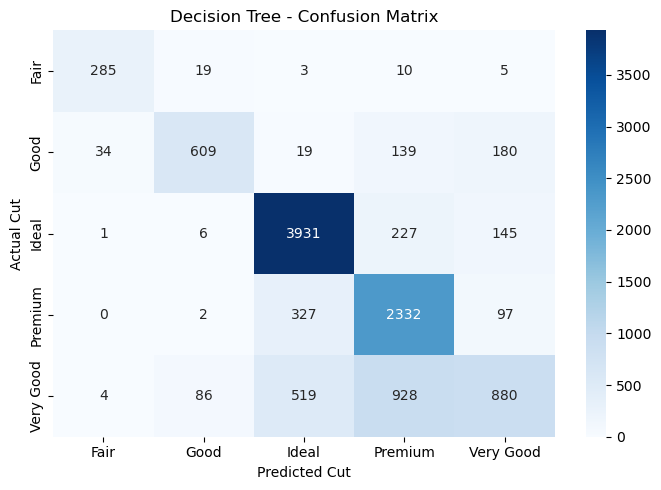

In [24]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=le.classes_,
    yticklabels=le.classes_
)

plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted Cut")
plt.ylabel("Actual Cut")
plt.tight_layout()
plt.show()

In [25]:
from sklearn.ensemble import RandomForestClassifier

rfc = RandomForestClassifier(
    n_estimators=100,
    criterion="entropy",
    random_state=0,
    n_jobs=-1
)

rfc.fit(X_train, y_train)

,n_estimators,100
,criterion,'entropy'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [26]:
y_pred_rf = rfc.predict(X_test)

In [27]:
cm1 = confusion_matrix(y_test, y_pred_rf)

asc1 = accuracy_score(y_test, y_pred_rf)

print("Confusion Matrix:")
print(cm1)

print("Accuracy:", asc1)

Confusion Matrix:
[[ 283   25    2    7    5]
 [  27  717   17   42  178]
 [   1   10 3976  172  151]
 [   0   11  323 2216  208]
 [   3  131  519  478 1286]]
Accuracy: 0.78587319243604


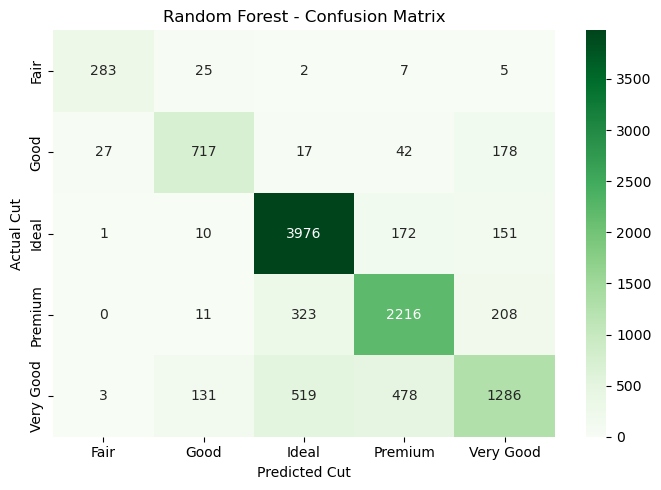

In [28]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm1,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=le.classes_,
    yticklabels=le.classes_
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Cut")
plt.ylabel("Actual Cut")
plt.tight_layout()
plt.show()

In [29]:
results = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],
    "Accuracy": [asc, asc1]
})

print(results)

           Model  Accuracy
0  Decision Tree  0.744994
1  Random Forest  0.785873


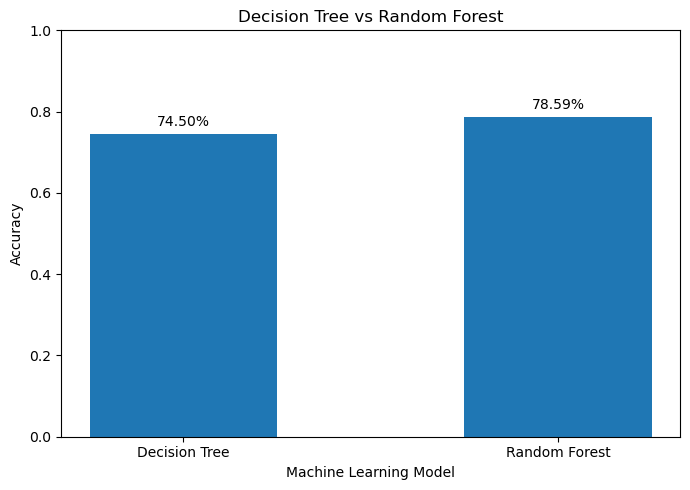

In [30]:
plt.figure(figsize=(7, 5))

plt.bar(
    results["Model"],
    results["Accuracy"],
    width=0.5
)

plt.title("Decision Tree vs Random Forest")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

for i, value in enumerate(results["Accuracy"]):
    plt.text(i, value + 0.02, f"{value:.2%}", ha="center")

plt.tight_layout()
plt.show()

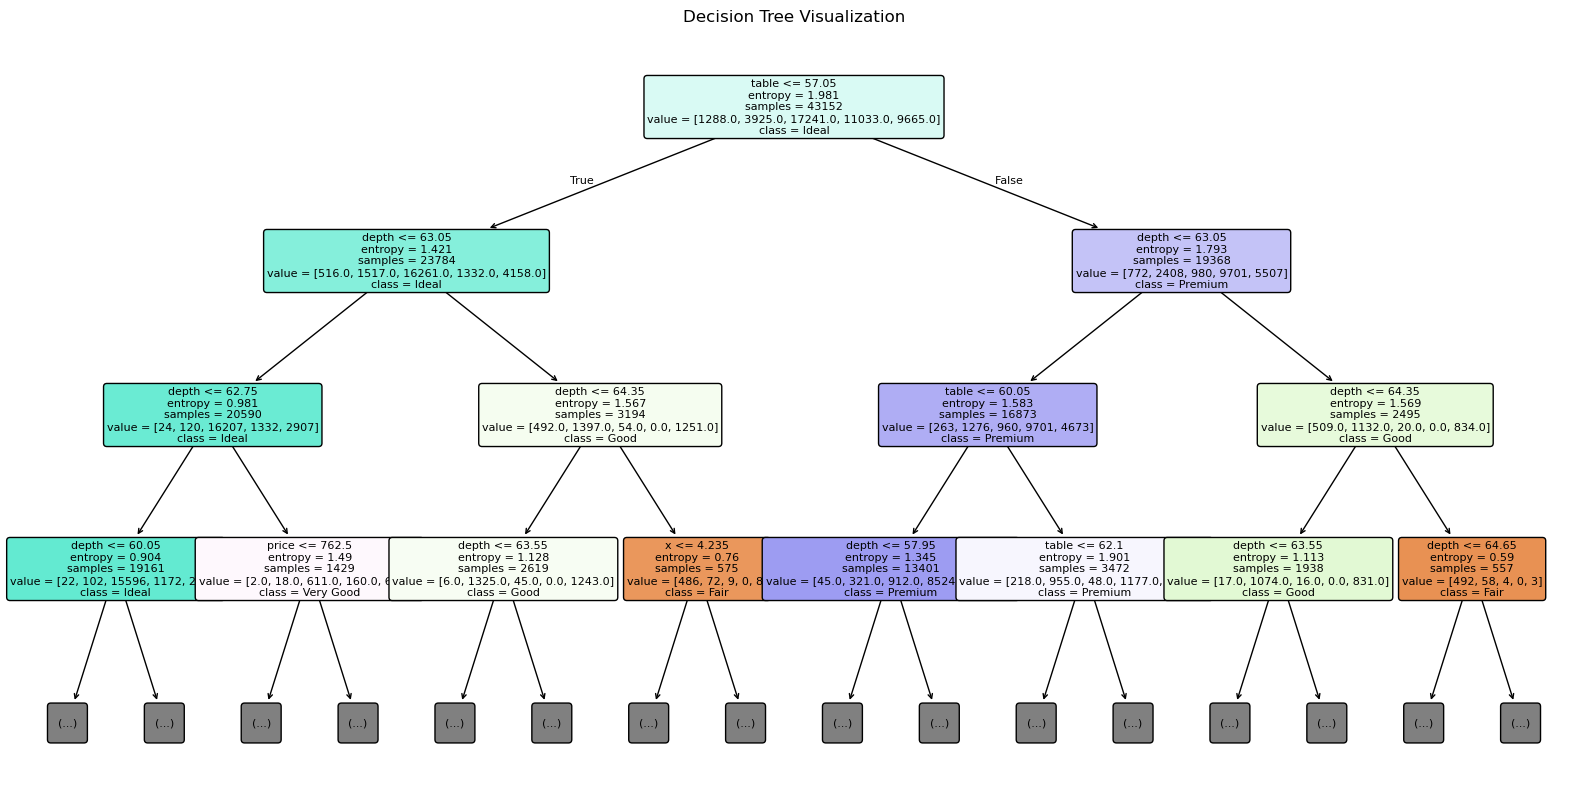

In [31]:
plt.figure(figsize=(20, 10))

plot_tree(
    classifier,
    feature_names=X.columns,
    class_names=le.classes_,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Decision Tree Visualization")
plt.show()

depth              0.264724
table              0.254015
x                  0.103602
y                  0.099023
price              0.091958
z                  0.068289
carat              0.048414
color_encoded      0.036376
clarity_encoded    0.033600
dtype: float64


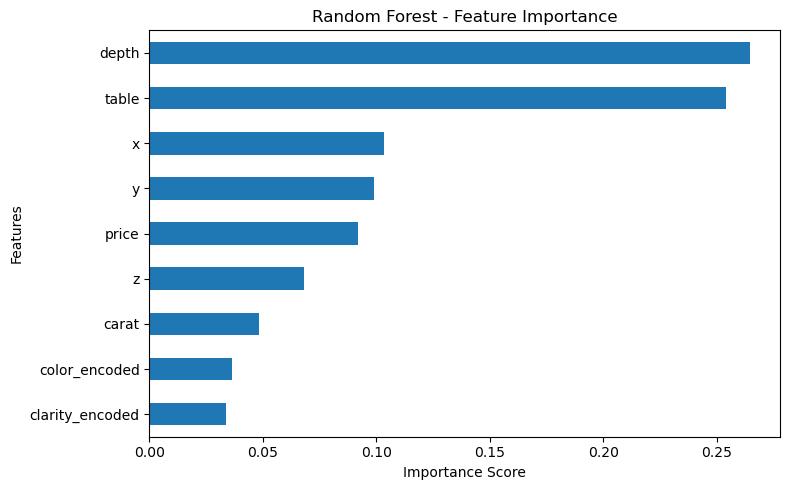

In [32]:
importance = pd.Series(
    rfc.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(importance)

plt.figure(figsize=(8, 5))

importance.sort_values().plot(kind="barh")

plt.title("Random Forest - Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

In [33]:
print("Decision Tree Classification Report")
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(len(le.classes_)),
    target_names=le.classes_,
    zero_division=0
))

print("Random Forest Classification Report")
print(classification_report(
    y_test,
    y_pred_rf,
    labels=np.arange(len(le.classes_)),
    target_names=le.classes_,
    zero_division=0
))

Decision Tree Classification Report
              precision    recall  f1-score   support

        Fair       0.88      0.89      0.88       322
        Good       0.84      0.62      0.72       981
       Ideal       0.82      0.91      0.86      4310
     Premium       0.64      0.85      0.73      2758
   Very Good       0.67      0.36      0.47      2417

    accuracy                           0.74     10788
   macro avg       0.77      0.73      0.73     10788
weighted avg       0.75      0.74      0.73     10788

Random Forest Classification Report
              precision    recall  f1-score   support

        Fair       0.90      0.88      0.89       322
        Good       0.80      0.73      0.76       981
       Ideal       0.82      0.92      0.87      4310
     Premium       0.76      0.80      0.78      2758
   Very Good       0.70      0.53      0.61      2417

    accuracy                           0.79     10788
   macro avg       0.80      0.77      0.78     10788
weigh

## Final Conclusion

1. The Diamond Dataset was used to build two machine learning models: Decision Tree and Random Forest.

2. Label Encoding was applied to convert categorical data into numerical values.

3. The dataset was divided into training and testing sets.

4. The Decision Tree model achieved an accuracy of **74.50%**.

5. The Random Forest model achieved an accuracy of **78.59%**.

6. Random Forest performed better than Decision Tree, with an improvement of approximately **4.09 percentage points** in accuracy.

7. Confusion matrices and graphs were used to evaluate and compare the performance of both models.

8. Based on the test accuracy, Random Forest was the better-performing model for predicting diamond cut quality in this experiment.

9. This project helped me understand data preprocessing, model training, prediction, evaluation, and visualization using Python and Scikit-learn.